In [ ]:
!nvidia-smi


Thu Nov 19 08:21:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import os
from numba import config

config.CUDA_ENABLE_PYNVJITLINK = 1
config.CUDA_LOW_OCCUPANCY_WARNINGS = 0

from concurrent.futures import ProcessPoolExecutor
import math
import time
import numpy as np

MAX_MACHINES = 128


def calculate_makespan(permutation, processing_times):
    n_machines = len(processing_times[0])
    times = [0] * n_machines
    for job in permutation:
        times[0] += processing_times[job][0]
        for m in range(1, n_machines):
            times[m] = max(times[m], times[m - 1]) + processing_times[job][m]
    return times[-1]


def run_neh(processing_times):
    n_jobs = len(processing_times)
    total_times = [(i, sum(processing_times[i])) for i in range(n_jobs)]
    total_times.sort(key=lambda x: x[1], reverse=True)

    current_seq = [total_times[0][0]]

    for i in range(1, n_jobs):
        job_to_insert = total_times[i][0]
        best_makespan = float("inf")
        best_seq = []

        for pos in range(len(current_seq) + 1):
            temp_seq = current_seq[:pos] + [job_to_insert] + current_seq[pos:]
            ms = calculate_makespan(temp_seq, processing_times)
            if ms < best_makespan:
                best_makespan = ms
                best_seq = temp_seq
        current_seq = best_seq

    return current_seq


def get_neighbors(permutation):
    neighbors = []
    n = len(permutation)
    for i in range(n):
        for j in range(i + 1, n):
            neighbor = list(permutation)
            neighbor[i], neighbor[j] = neighbor[j], neighbor[i]
            neighbors.append((neighbor, (i, j)))
    return neighbors


def _evaluate_neighbor_chunk(args):
    chunk, processing_times, tabu_list, iteration, best_ms = args
    best_chunk_neighbor = None
    best_chunk_ms = float("inf")
    best_chunk_move = None

    for neighbor, move in chunk:
        ms = calculate_makespan(neighbor, processing_times)
        is_tabu = move in tabu_list and tabu_list[move] > iteration

        if not is_tabu or ms < best_ms:
            if ms < best_chunk_ms:
                best_chunk_neighbor = neighbor
                best_chunk_ms = ms
                best_chunk_move = move

    return best_chunk_neighbor, best_chunk_ms, best_chunk_move


# Pula procesów CPU tworzona raz przed inicjalizacją CUDA (bezpieczne dla Linux/Colab)
WORKERS = os.cpu_count() or 2
if "_COLAB_CPU_POOL" not in globals():
    _COLAB_CPU_POOL = ProcessPoolExecutor(max_workers=WORKERS)

from numba import cuda, int32


def run_tabu_search(processing_times, initial_sol, max_iter=100, tabu_tenure=7):
    start_time = time.time()
    best_sol = list(initial_sol)
    best_ms = calculate_makespan(best_sol, processing_times)
    best_time = 0.0
    current_sol = list(initial_sol)
    tabu_list = {}

    for iteration in range(max_iter):
        neighbors = get_neighbors(current_sol)
        best_neighbor = None
        best_neighbor_ms = float("inf")
        best_move = None

        for neighbor, move in neighbors:
            ms = calculate_makespan(neighbor, processing_times)
            is_tabu = move in tabu_list and tabu_list[move] > iteration

            if not is_tabu or ms < best_ms:
                if ms < best_neighbor_ms:
                    best_neighbor = neighbor
                    best_neighbor_ms = ms
                    best_move = move

        if best_neighbor is None:
            break

        current_sol = best_neighbor
        if best_neighbor_ms < best_ms:
            best_sol = list(best_neighbor)
            best_ms = best_neighbor_ms
            best_time = time.time() - start_time

        tabu_list[best_move] = iteration + tabu_tenure

    return best_sol, best_ms, best_time, time.time() - start_time


def run_parallel_tabu_search(
    processing_times, initial_sol, max_iter=100, tabu_tenure=7, num_workers=WORKERS
):
    start_time = time.time()
    best_sol = list(initial_sol)
    best_ms = calculate_makespan(best_sol, processing_times)
    best_time = 0.0
    current_sol = list(initial_sol)
    tabu_list = {}

    for iteration in range(max_iter):
        neighbors = get_neighbors(current_sol)
        if not neighbors:
            break

        chunk_size = max(1, math.ceil(len(neighbors) / num_workers))
        chunks = [
            neighbors[i : i + chunk_size]
            for i in range(0, len(neighbors), chunk_size)
        ]
        tasks = [
            (chunk, processing_times, tabu_list, iteration, best_ms)
            for chunk in chunks
        ]

        best_neighbor = None
        best_neighbor_ms = float("inf")
        best_move = None

        for cand_neighbor, cand_ms, cand_move in _COLAB_CPU_POOL.map(
            _evaluate_neighbor_chunk, tasks
        ):
            if cand_neighbor is not None and cand_ms < best_neighbor_ms:
                best_neighbor = cand_neighbor
                best_neighbor_ms = cand_ms
                best_move = cand_move

        if best_neighbor is None:
            break

        current_sol = best_neighbor
        if best_neighbor_ms < best_ms:
            best_sol = list(best_neighbor)
            best_ms = best_neighbor_ms
            best_time = time.time() - start_time

        tabu_list[best_move] = iteration + tabu_tenure

    return best_sol, best_ms, best_time, time.time() - start_time


@cuda.jit
def _evaluate_neighborhood_cuda(current_sol, proc_times, moves, makespans):
    tid = cuda.grid(1)
    if tid >= moves.shape[0]:
        return

    swap_i = moves[tid, 0]
    swap_j = moves[tid, 1]
    n_jobs = current_sol.shape[0]
    n_machines = proc_times.shape[1]

    times = cuda.local.array(MAX_MACHINES, dtype=int32)
    for m in range(n_machines):
        times[m] = 0

    for idx in range(n_jobs):
        if idx == swap_i:
            job = current_sol[swap_j]
        elif idx == swap_j:
            job = current_sol[swap_i]
        else:
            job = current_sol[idx]

        times[0] += proc_times[job, 0]
        for m in range(1, n_machines):
            prev_m = times[m - 1]
            curr_m = times[m]
            if prev_m > curr_m:
                times[m] = prev_m + proc_times[job, m]
            else:
                times[m] = curr_m + proc_times[job, m]

    makespans[tid] = times[n_machines - 1]


def run_gpu_tabu_search(
    processing_times, initial_sol, max_iter=100, tabu_tenure=7
):
    n_jobs = len(processing_times)
    n_machines = len(processing_times[0])
    if n_machines > MAX_MACHINES:
        raise ValueError(
            f"Liczba maszyn ({n_machines}) przekracza limit {MAX_MACHINES}."
        )

    start_time = time.time()

    proc_times_np = np.array(processing_times, dtype=np.int32)
    current_sol_np = np.array(initial_sol, dtype=np.int32)

    moves_list = [(i, j) for i in range(n_jobs) for j in range(i + 1, n_jobs)]
    num_neighbors = len(moves_list)
    if num_neighbors == 0:
        ms = calculate_makespan(initial_sol, processing_times)
        return list(initial_sol), ms, 0.0, time.time() - start_time

    moves_np = np.array(moves_list, dtype=np.int32)

    d_proc_times = cuda.to_device(proc_times_np)
    d_moves = cuda.to_device(moves_np)
    d_current_sol = cuda.device_array(n_jobs, dtype=np.int32)
    d_makespans = cuda.device_array(num_neighbors, dtype=np.int32)

    threads_per_block = 256
    blocks_per_grid = math.ceil(num_neighbors / threads_per_block)

    best_sol = list(initial_sol)
    best_ms = calculate_makespan(best_sol, processing_times)
    best_time = 0.0
    tabu_list = {}

    for iteration in range(max_iter):
        d_current_sol.copy_to_device(current_sol_np)

        _evaluate_neighborhood_cuda[blocks_per_grid, threads_per_block](
            d_current_sol, d_proc_times, d_moves, d_makespans
        )
        makespans_host = d_makespans.copy_to_host()

        best_idx = -1
        best_neighbor_ms = float("inf")

        for idx in range(num_neighbors):
            ms = int(makespans_host[idx])
            move = moves_list[idx]
            is_tabu = move in tabu_list and tabu_list[move] > iteration

            if not is_tabu or ms < best_ms:
                if ms < best_neighbor_ms:
                    best_neighbor_ms = ms
                    best_idx = idx

        if best_idx == -1:
            break

        move_i, move_j = moves_list[best_idx]
        current_sol_np[move_i], current_sol_np[move_j] = (
            current_sol_np[move_j],
            current_sol_np[move_i],
        )

        if best_neighbor_ms < best_ms:
            best_sol = current_sol_np.tolist()
            best_ms = best_neighbor_ms
            best_time = time.time() - start_time

        tabu_list[(move_i, move_j)] = iteration + tabu_tenure

    return best_sol, best_ms, best_time, time.time() - start_time


def load_instances(file_path):
    with open(file_path, "r") as f:
        tokens = f.read().split()

    instances = []
    i = 0
    while i < len(tokens):
        if tokens[i].startswith("data."):
            name = tokens[i].replace(":", "")
            i += 1
            n = int(tokens[i])
            m = int(tokens[i + 1])
            i += 2

            processing_times = []
            for _ in range(n):
                row = []
                for _ in range(m):
                    row.append(int(tokens[i]))
                    i += 1
                processing_times.append(row)

            ref_ms = None
            if i < len(tokens) and tokens[i] == "neh:":
                i += 1
                ref_ms = int(tokens[i])
                i += 1
                while i < len(tokens) and not tokens[i].startswith("data."):
                    i += 1

            instances.append((name, processing_times, ref_ms))
        else:
            i += 1
    return instances


if not cuda.is_available():
    raise RuntimeError(
        "Nie wykryto GPU! Zmień typ środowiska wykonawczego na T4 GPU."
    )

instances = load_instances("neh.data.txt")
gpu_name = cuda.get_current_device().name

# Rozgrzewka kompilatora JIT CUDA
run_gpu_tabu_search([[1, 1], [1, 1]], [0, 1], max_iter=1)

print(f"CPU workers: {WORKERS} | GPU: {gpu_name}")
print(
    f"{'Instance':<9} | {'Cmax':<7} | {'Seq Time':<9} | {'CPU Time':<9} | {'CPU Acc':<8} | {'GPU Time':<9} | {'GPU Acc':<8}"
)
print("-" * 77)

for name, processing_times, _ in instances:
    initial_sol = run_neh(processing_times)

    _, seq_ms, _, seq_time = run_tabu_search(processing_times, initial_sol)
    _, cpu_ms, _, cpu_time = run_parallel_tabu_search(
        processing_times, initial_sol
    )
    _, gpu_ms, _, gpu_time = run_gpu_tabu_search(processing_times, initial_sol)

    assert seq_ms == cpu_ms == gpu_ms

    cpu_acc = seq_time / cpu_time if cpu_time > 0 else 0.0
    gpu_acc = seq_time / gpu_time if gpu_time > 0 else 0.0

    print(
        f"{name:<9} | {gpu_ms:<7} | {seq_time:<9.5f} | {cpu_time:<9.5f} | {cpu_acc:<7.2f}x | {gpu_time:<9.5f} | {gpu_acc:<7.2f}x"
    )


CPU workers: 2 | GPU: Tesla T4
Instance  | Cmax    | Seq Time  | CPU Time  | CPU Acc  | GPU Time  | GPU Acc 
-----------------------------------------------------------------------------
data.000  | 32      | 0.00011   | 0.02874   | 0.00   x | 0.00542   | 0.02   x
data.001  | 1286    | 0.25507   | 0.34910   | 0.73   x | 0.03325   | 7.67   x
data.002  | 1360    | 0.24482   | 0.34448   | 0.71   x | 0.03043   | 8.05   x
data.003  | 1081    | 0.26529   | 0.33951   | 0.78   x | 0.03121   | 8.50   x
data.004  | 1299    | 0.25066   | 0.34322   | 0.73   x | 0.03182   | 7.88   x
data.005  | 1277    | 0.26065   | 0.34260   | 0.76   x | 0.02974   | 8.77   x
data.006  | 1224    | 0.24951   | 0.35242   | 0.71   x | 0.02986   | 8.36   x
data.007  | 1251    | 0.25518   | 0.33825   | 0.75   x | 0.02933   | 8.70   x
data.008  | 1206    | 0.27147   | 0.34218   | 0.79   x | 0.02945   | 9.22   x
data.009  | 1255    | 0.25380   | 0.35396   | 0.72   x | 0.02995   | 8.47   x
data.010  | 1108    | 0.24396   |

Rozmiar (n×m)  | Seq [s]    | CPU Par [s] | GPU [s]    | Acc CPU  | Acc GPU 
--------------------------------------------------------------------------
4x3            | 0.0001     | 0.0071      | 0.0030     | 0.01   x | 0.04   x
20x5           | 0.2455     | 0.3565      | 0.0296     | 0.69   x | 8.29   x
20x10          | 0.6902     | 0.9255      | 0.0491     | 0.75   x | 14.05  x
50x5           | 4.9591     | 4.4535      | 0.0627     | 1.11   x | 79.04  x
20x20          | 0.9255     | 1.1833      | 0.0625     | 0.78   x | 14.80  x
50x10          | 10.6585    | 9.5091      | 0.0985     | 1.12   x | 108.20 x


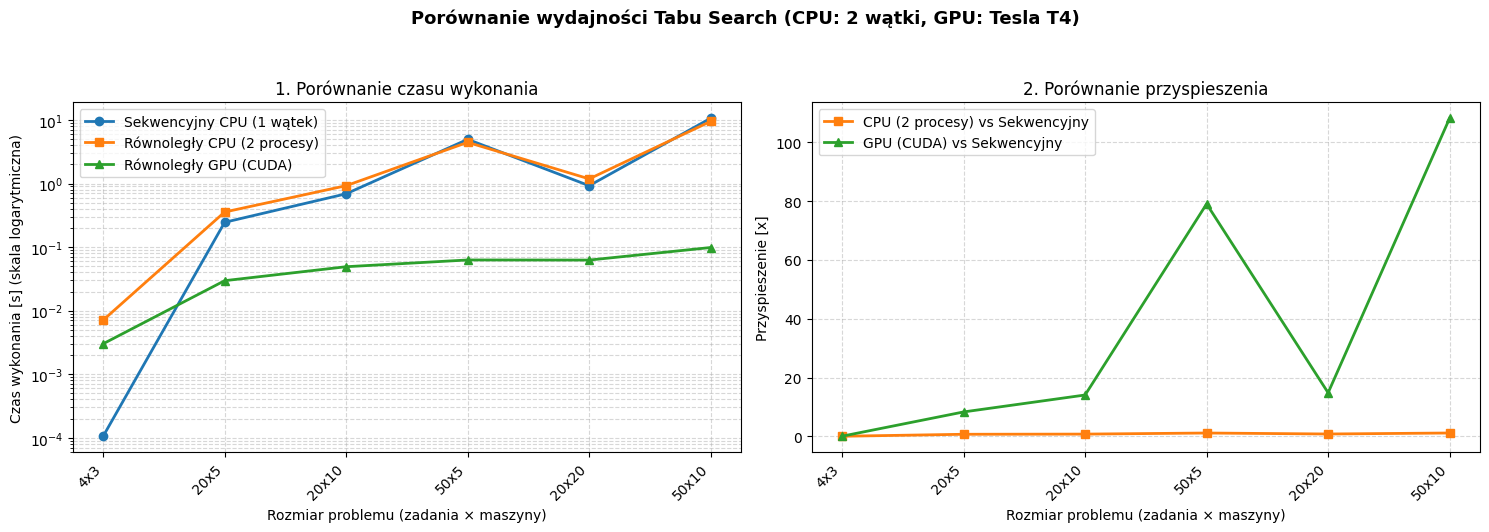

In [7]:
from collections import defaultdict
import os
import time
import matplotlib.pyplot as plt
import numpy as np

# Sprawdzenie, czy komórka z Zadaniem 2 została wcześniej uruchomiona
required_funcs = [
    "run_tabu_search",
    "run_parallel_tabu_search",
    "run_gpu_tabu_search",
    "load_instances",
    "run_neh",
]
if not all(fn in globals() for fn in required_funcs):
    raise RuntimeError(
        "Komórka z obliczeniami do zadania nie została uruchomiona."
    )

workers_count = globals().get("WORKERS", os.cpu_count() or 2)
device_gpu_name = globals().get("gpu_name", "GPU CUDA")

# 1. Grupowanie instancji według rozmiaru problemu (n zadań x m maszyn)
raw_instances = load_instances("neh.data.txt")
grouped_by_size = defaultdict(list)
for name, proc_times, _ in raw_instances:
    n_jobs = len(proc_times)
    n_machines = len(proc_times[0])
    grouped_by_size[(n_jobs, n_machines)].append((name, proc_times))

if len(grouped_by_size) < 4:
    rng = np.random.default_rng(42)
    for n_syn, m_syn in [(20, 10), (50, 10), (100, 10), (150, 10), (200, 10)]:
        if (n_syn, m_syn) not in grouped_by_size:
            syn_matrix = rng.integers(1, 100, size=(n_syn, m_syn)).tolist()
            grouped_by_size[(n_syn, m_syn)].append(
                (f"syn_{n_syn}x{m_syn}", syn_matrix)
            )

sorted_sizes = sorted(
    grouped_by_size.keys(), key=lambda x: (x[0] * x[1], x[0])
)

results = []
print(
    f"{'Rozmiar (n×m)':<14} | {'Seq [s]':<10} | {'CPU Par [s]':<11} | {'GPU [s]':<10} | {'Acc CPU':<8} | {'Acc GPU':<8}"
)
print("-" * 74)

# 2. Pomiar czasu wykonania i obliczenie przyspieszenia dla każdego rozmiaru
for n_jobs, n_machines in sorted_sizes:
    sample_instances = grouped_by_size[(n_jobs, n_machines)][:2]
    seq_times, cpu_times, gpu_times = [], [], []

    for _, proc_times in sample_instances:
        init_sol = run_neh(proc_times)

        if n_jobs > 200:
            _, _, _, t_seq_part = run_tabu_search(
                proc_times, init_sol, max_iter=10
            )
            t_seq = t_seq_part * 10.0
        else:
            _, _, _, t_seq = run_tabu_search(proc_times, init_sol, max_iter=100)

        _, _, _, t_cpu = run_parallel_tabu_search(
            proc_times, init_sol, max_iter=100
        )
        _, _, _, t_gpu = run_gpu_tabu_search(proc_times, init_sol, max_iter=100)

        seq_times.append(t_seq)
        cpu_times.append(t_cpu)
        gpu_times.append(t_gpu)

    avg_seq = float(np.mean(seq_times))
    avg_cpu = float(np.mean(cpu_times))
    avg_gpu = float(np.mean(gpu_times))

    acc_cpu = avg_seq / avg_cpu if avg_cpu > 0 else 0.0
    acc_gpu = avg_seq / avg_gpu if avg_gpu > 0 else 0.0

    results.append({
        "label": f"{n_jobs}x{n_machines}",
        "seq": avg_seq,
        "cpu": avg_cpu,
        "gpu": avg_gpu,
        "acc_cpu": acc_cpu,
        "acc_gpu": acc_gpu,
    })

    print(
        f"{f'{n_jobs}x{n_machines}':<14} | {avg_seq:<10.4f} | {avg_cpu:<11.4f} | {avg_gpu:<10.4f} | {acc_cpu:<7.2f}x | {acc_gpu:<7.2f}x"
    )

# 3. Rysowanie wyłącznie dwóch wykresów: 1. Czas wykonania, 2. Przyspieszenie
labels = [r["label"] for r in results]
x = np.arange(len(labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))
fig.suptitle(
    f"Porównanie wydajności Tabu Search (CPU: {workers_count} wątki, GPU: {device_gpu_name})",
    fontsize=13,
    fontweight="bold",
)

# Wykres 1: Czas wykonania
ax1.plot(
    x,
    [r["seq"] for r in results],
    marker="o",
    linewidth=2,
    label="Sekwencyjny CPU (1 wątek)",
)
ax1.plot(
    x,
    [r["cpu"] for r in results],
    marker="s",
    linewidth=2,
    label=f"Równoległy CPU ({workers_count} procesy)",
)
ax1.plot(
    x,
    [r["gpu"] for r in results],
    marker="^",
    linewidth=2,
    label="Równoległy GPU (CUDA)",
)
ax1.set_yscale("log")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=45, ha="right")
ax1.set_title("1. Porównanie czasu wykonania")
ax1.set_xlabel("Rozmiar problemu (zadania × maszyny)")
ax1.set_ylabel("Czas wykonania [s] (skala logarytmiczna)")
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend()

# Wykres 2: Przyspieszenie (akceleracja)
ax2.plot(
    x,
    [r["acc_cpu"] for r in results],
    marker="s",
    linewidth=2,
    color="tab:orange",
    label=f"CPU ({workers_count} procesy) vs Sekwencyjny",
)
ax2.plot(
    x,
    [r["acc_gpu"] for r in results],
    marker="^",
    linewidth=2,
    color="tab:green",
    label="GPU (CUDA) vs Sekwencyjny",
)
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=45, ha="right")
ax2.set_title("2. Porównanie przyspieszenia")
ax2.set_xlabel("Rozmiar problemu (zadania × maszyny)")
ax2.set_ylabel("Przyspieszenie [x]")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout(rect=[0, 0.02, 1, 0.94])
plt.savefig("porownanie_czas_przyspieszenie.png", dpi=150)
plt.show()